In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# K folds (5)


FOLD 1/5


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 1/50


Training: 100%|██████████| 20/20 [00:24<00:00,  1.23s/it]


Train Loss: 0.5320 (CE: 0.5919, Dice: 0.4721), Train Accuracy: 0.6941


...

Validation Loss: 0.5424 (CE: 0.5178, Dice: 0.5669), Validation Accuracy: 0.7156

  -> No improvement for 7/8 epochs
Epoch 15/50


Training: 100%|██████████| 20/20 [00:24<00:00,  1.23s/it]


Train Loss: 0.4762 (CE: 0.5399, Dice: 0.4125), Train Accuracy: 0.7199


Validating: 100%|██████████| 5/5 [00:06<00:00,  1.22s/it]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Validation Loss: 0.5506 (CE: 0.5309, Dice: 0.5703), Validation Accuracy: 0.7000

  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 15. Best Val Accuracy: 0.7312
Training completed in time:  0:07:44.988629

Fold 5 Best Validation Accuracy: 0.7312

5-FOLD CROSS-VALIDATION RESULTS
Fold 1 Validation Accuracy: 0.7812
Fold 2 Validation Accuracy: 0.7562
Fold 3 Validation Accuracy: 0.7391
Fold 4 Validation Accuracy: 0.7594
Fold 5 Validation Accuracy: 0.7312

Mean CV Accuracy: 0.7534
CV Standard Deviation: 0.0174
Best CV Accuracy: 0.7812
Best model loaded with validation accuracy: 0.7812


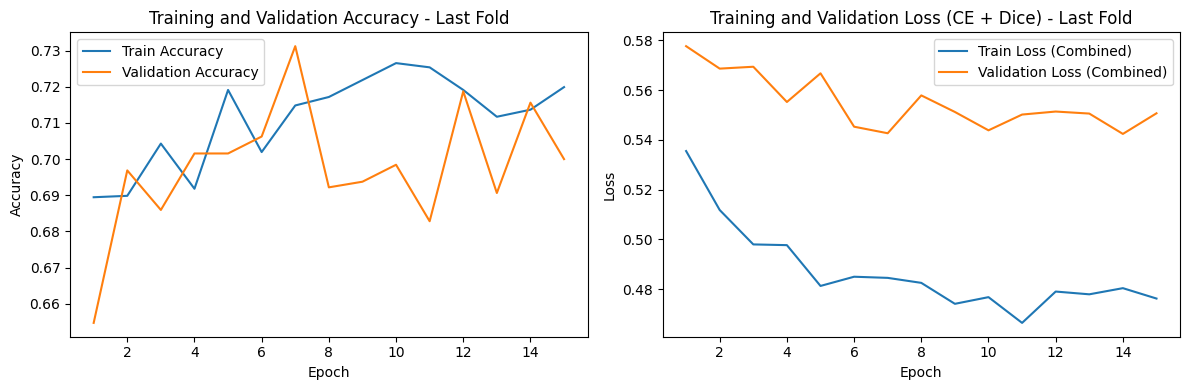

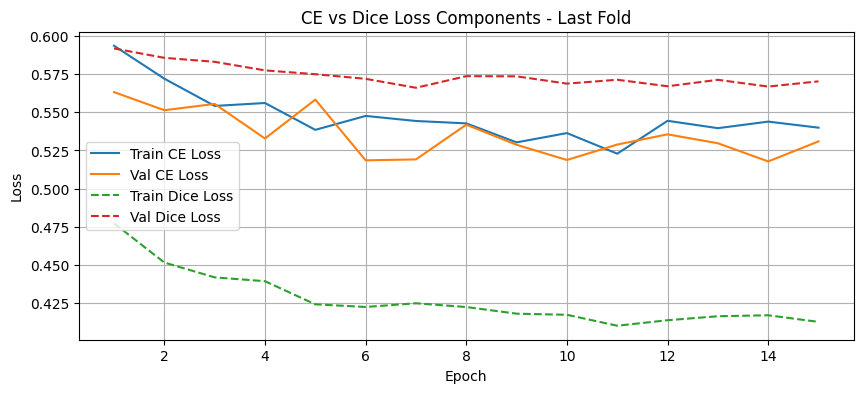

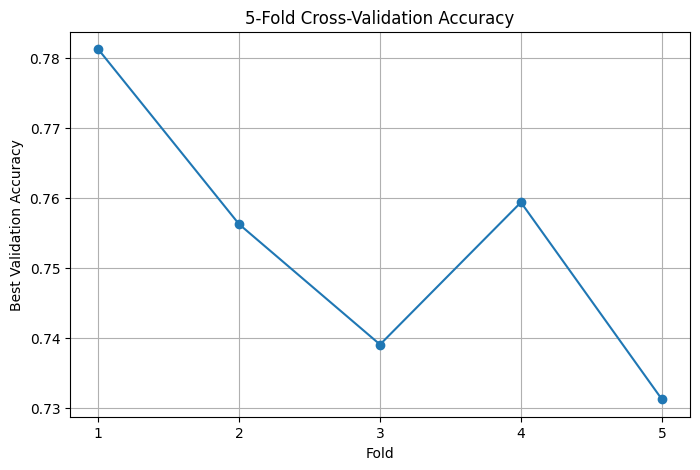

Test accuracy: 0.8253
Precision (weighted): 0.8679
Recall (weighted):    0.8535
F1-score (weighted):  0.8378

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.84      0.99      0.91      1052
  Appears normal       0.95      0.51      0.66       416

        accuracy                           0.85      1468
       macro avg       0.89      0.75      0.79      1468
    weighted avg       0.87      0.85      0.84      1468

Confusion Matrix:
[[1040   12]
 [ 203  213]]


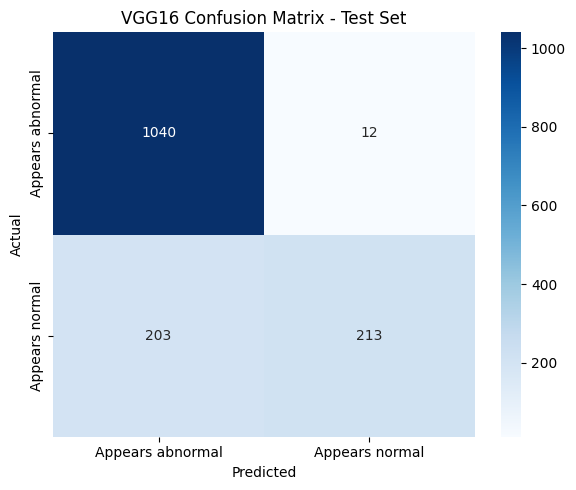


Summary:
Mean 5-Fold CV Accuracy: 0.7534
CV Standard Deviation: 0.0174
Best CV Accuracy: 0.7812
Final Test Accuracy: 0.8253
Final Test Precision: 0.8679, Recall: 0.8535, F1-score: 0.8378


In [7]:
import torch
import torch.nn as nn
import numpy as np
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
from datetime import datetime
from sklearn.model_selection import KFold

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths for train and test sets
train_path = '/kaggle/working/PCOSGen-train/train'
test_path = '/kaggle/working/PCOSGen-train/test'

# Preprocessing transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(40),
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop(224),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])
}

# Load datasets
train_dataset = datasets.ImageFolder(
    train_path,
    transform=data_transforms['train']
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=data_transforms['test']
)

# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# DataLoader for TEST only
batch_size = 128

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Number of classes
num_classes = len(train_dataset.classes)


# ============================================================
# Dice Loss + Combined CrossEntropy + Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth)
            / (union + self.smooth)
        )

        return 1. - dice_score.mean()


class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Function to calculate accuracy
# ============================================================

def calculate_accuracy(y_pred, y_true):

    _, predicted = torch.max(
        y_pred,
        1
    )

    correct = (
        predicted == y_true
    ).sum().item()

    return correct / len(y_true)


# ============================================================
# Overall best model
# ============================================================

overall_best_accuracy = 0.0

model_save_path = 'best_vgg_model.pth'

patience = 8

num_epochs = 50

fold_accuracies = []


# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

for fold, (train_indices, val_indices) in enumerate(
        kfold.split(train_dataset), 1):

    print("\n" + "=" * 60)
    print(f"FOLD {fold}/5")
    print("=" * 60)

    # --------------------------------------------------------
    # Train / Validation subsets
    # --------------------------------------------------------

    train_subset = Subset(
        train_dataset,
        train_indices
    )

    val_subset = Subset(
        train_dataset,
        val_indices
    )

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_subset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=batch_size,
        shuffle=False
    )

    # --------------------------------------------------------
    # Fresh VGG16 for every fold
    # --------------------------------------------------------

    vgg = models.vgg16(
        pretrained=True
    )

    # Freeze the VGG layers
    for param in vgg.parameters():
        param.requires_grad = False

    # Modify classifier
    vgg.classifier[6] = nn.Linear(
        vgg.classifier[6].in_features,
        num_classes
    )

    # Move model to device
    vgg = vgg.to(device)

    # Fresh optimizer for every fold
    optimizer = optim.Adam(
        vgg.classifier[6].parameters()
    )

    # --------------------------------------------------------
    # Graph data for this fold
    # --------------------------------------------------------

    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    train_ce_losses = []
    train_dice_losses = []

    val_ce_losses = []
    val_dice_losses = []

    # --------------------------------------------------------
    # Early stopping for this fold
    # --------------------------------------------------------

    best_val_accuracy = 0.0

    epochs_no_improve = 0

    fold_model_path = f'best_vgg_model_fold_{fold}.pth'

    # ========================================================
    # Training
    # ========================================================

    start = datetime.now()

    for epoch in range(num_epochs):

        print(
            f'Epoch {epoch+1}/{num_epochs}'
        )

        vgg.train()

        running_loss = 0.0
        running_ce = 0.0
        running_dice = 0.0
        running_accuracy = 0.0

        # ----------------------------------------------------
        # Training phase
        # ----------------------------------------------------

        for inputs, labels in tqdm(
            train_loader,
            desc='Training'
        ):

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = vgg(inputs)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            running_accuracy += calculate_accuracy(
                outputs,
                labels
            )

        epoch_train_loss = (
            running_loss / len(train_loader)
        )

        epoch_train_ce = (
            running_ce / len(train_loader)
        )

        epoch_train_dice = (
            running_dice / len(train_loader)
        )

        epoch_train_accuracy = (
            running_accuracy / len(train_loader)
        )

        train_losses.append(
            epoch_train_loss
        )

        train_ce_losses.append(
            epoch_train_ce
        )

        train_dice_losses.append(
            epoch_train_dice
        )

        train_accuracies.append(
            epoch_train_accuracy
        )

        print(
            f"Train Loss: {epoch_train_loss:.4f} "
            f"(CE: {epoch_train_ce:.4f}, "
            f"Dice: {epoch_train_dice:.4f}), "
            f"Train Accuracy: {epoch_train_accuracy:.4f}"
        )

        # ----------------------------------------------------
        # Validation phase
        # ----------------------------------------------------

        vgg.eval()

        val_loss = 0.0
        val_ce = 0.0
        val_dice = 0.0
        val_accuracy = 0.0

        with torch.no_grad():

            for inputs, labels in tqdm(
                val_loader,
                desc='Validating'
            ):

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = vgg(inputs)

                loss, ce, dice = criterion(
                    outputs,
                    labels
                )

                val_loss += loss.item()
                val_ce += ce.item()
                val_dice += dice.item()

                val_accuracy += calculate_accuracy(
                    outputs,
                    labels
                )

        epoch_val_loss = (
            val_loss / len(val_loader)
        )

        epoch_val_ce = (
            val_ce / len(val_loader)
        )

        epoch_val_dice = (
            val_dice / len(val_loader)
        )

        epoch_val_accuracy = (
            val_accuracy / len(val_loader)
        )

        val_losses.append(
            epoch_val_loss
        )

        val_ce_losses.append(
            epoch_val_ce
        )

        val_dice_losses.append(
            epoch_val_dice
        )

        val_accuracies.append(
            epoch_val_accuracy
        )

        print(
            f"Validation Loss: {epoch_val_loss:.4f} "
            f"(CE: {epoch_val_ce:.4f}, "
            f"Dice: {epoch_val_dice:.4f}), "
            f"Validation Accuracy: "
            f"{epoch_val_accuracy:.4f}\n"
        )

        # ----------------------------------------------------
        # Save best model
        # ----------------------------------------------------

        if epoch_val_accuracy > best_val_accuracy:

            best_val_accuracy = epoch_val_accuracy

            epochs_no_improve = 0

            torch.save(
                vgg.state_dict(),
                fold_model_path
            )

            print(
                f"  -> Model saved at epoch "
                f"{epoch+1} with validation accuracy "
                f"{best_val_accuracy:.4f}"
            )

            # Save overall best model
            if epoch_val_accuracy > overall_best_accuracy:

                overall_best_accuracy = (
                    epoch_val_accuracy
                )

                torch.save(
                    vgg.state_dict(),
                    model_save_path
                )

        else:

            epochs_no_improve += 1

            print(
                f"  -> No improvement for "
                f"{epochs_no_improve}/{patience} epochs"
            )

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if epochs_no_improve >= patience:

            print(
                f"\nEarly stopping triggered at "
                f"epoch {epoch+1}. "
                f"Best Val Accuracy: "
                f"{best_val_accuracy:.4f}"
            )

            break

    duration = datetime.now() - start

    print(
        "Training completed in time: ",
        duration
    )

    # --------------------------------------------------------
    # Store fold result
    # --------------------------------------------------------

    fold_accuracies.append(
        best_val_accuracy
    )

    print(
        f'\nFold {fold} Best Validation Accuracy: '
        f'{best_val_accuracy:.4f}'
    )


# ============================================================
# 5-FOLD RESULTS
# ============================================================

print("\n" + "=" * 60)
print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 60)

for i, accuracy in enumerate(
        fold_accuracies, 1):

    print(
        f"Fold {i} Validation Accuracy: "
        f"{accuracy:.4f}"
    )

mean_cv_accuracy = np.mean(
    fold_accuracies
)

std_cv_accuracy = np.std(
    fold_accuracies
)

print(
    f"\nMean CV Accuracy: "
    f"{mean_cv_accuracy:.4f}"
)

print(
    f"CV Standard Deviation: "
    f"{std_cv_accuracy:.4f}"
)

print(
    f"Best CV Accuracy: "
    f"{overall_best_accuracy:.4f}"
)


# ============================================================
# Load the overall best model
# ============================================================

vgg = models.vgg16(
    pretrained=False
)

for param in vgg.parameters():
    param.requires_grad = False

vgg.classifier[6] = nn.Linear(
    vgg.classifier[6].in_features,
    num_classes
)

vgg = vgg.to(device)

vgg.load_state_dict(
    torch.load(
        model_save_path,
        map_location=device
    )
)

print(
    f"Best model loaded with validation accuracy: "
    f"{overall_best_accuracy:.4f}"
)


# ============================================================
# Plotting - LAST FOLD
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(12, 4)
)

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    train_accuracies,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accuracies,
    label='Validation Accuracy'
)

plt.title(
    'Training and Validation Accuracy - Last Fold'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()


# Loss plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Validation Loss (Combined)'
)

plt.title(
    'Training and Validation Loss (CE + Dice) - Last Fold'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# CE vs Dice components
# ============================================================

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    epochs_range,
    train_ce_losses,
    label='Train CE Loss'
)

plt.plot(
    epochs_range,
    val_ce_losses,
    label='Val CE Loss'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.title(
    'CE vs Dice Loss Components - Last Fold'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 5-Fold Validation Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    range(1, 6),
    fold_accuracies,
    marker='o'
)

plt.xlabel('Fold')

plt.ylabel('Best Validation Accuracy')

plt.title(
    '5-Fold Cross-Validation Accuracy'
)

plt.xticks(
    range(1, 6)
)

plt.grid(True)

plt.show()


# ============================================================
# Testing the model
# TEST SET USED ONLY HERE
# ============================================================

vgg.eval()

test_accuracy = 0.0

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = vgg(inputs)

        test_accuracy += calculate_accuracy(
            outputs,
            labels
        )

test_accuracy /= len(test_loader)

print(
    f'Test accuracy: {test_accuracy:.4f}'
)


# ============================================================
# ADDITIONAL EVALUATION METRICS
# ============================================================

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


vgg.eval()

all_labels = []
all_predictions = []


with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = vgg(inputs)

        _, predicted = torch.max(
            outputs,
            1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predicted.cpu().numpy()
        )


all_labels = np.array(
    all_labels
)

all_predictions = np.array(
    all_predictions
)

class_names = test_dataset.classes


# Precision, Recall, F1
precision = precision_score(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)


print(
    f"Precision (weighted): {precision:.4f}"
)

print(
    f"Recall (weighted):    {recall:.4f}"
)

print(
    f"F1-score (weighted):  {f1:.4f}"
)


# Classification report
print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")

print(cm)


plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title(
    'VGG16 Confusion Matrix - Test Set'
)

plt.tight_layout()

plt.show()


# ============================================================
# Summary
# ============================================================

print('\nSummary:')

print(
    f'Mean 5-Fold CV Accuracy: '
    f'{mean_cv_accuracy:.4f}'
)

print(
    f'CV Standard Deviation: '
    f'{std_cv_accuracy:.4f}'
)

print(
    f'Best CV Accuracy: '
    f'{overall_best_accuracy:.4f}'
)

print(
    f'Final Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1-score: {f1:.4f}'
)

# Normal

Using device: cuda

Classes: ['Appears abnormal', 'Appears normal']
Total training images: 3200
Total test images: 1468

Training images: 2720
Validation images: 480
Test images: 1468
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 103MB/s] 


Epoch [1/50], Train Loss: 0.5777, Train Accuracy: 0.6669, Val Loss: 0.6202, Val Accuracy: 0.5729
Saving the best model with validation accuracy: 0.5729
Epoch [2/50], Train Loss: 0.5107, Train Accuracy: 0.6963, Val Loss: 0.5601, Val Accuracy: 0.6792
Saving the best model with validation accuracy: 0.6792
Epoch [3/50], Train Loss: 0.4870, Train Accuracy: 0.7070, Val Loss: 0.5483, Val Accuracy: 0.6354
Epoch [4/50], Train Loss: 0.4835, Train Accuracy: 0.7235, Val Loss: 0.5139, Val Accuracy: 0.7000
Saving the best model with validation accuracy: 0.7000
Epoch [5/50], Train Loss: 0.4693, Train Accuracy: 0.7430, Val Loss: 0.6470, Val Accuracy: 0.6542
Epoch [6/50], Train Loss: 0.4652, Train Accuracy: 0.7301, Val Loss: 0.4937, Val Accuracy: 0.6979
Epoch [7/50], Train Loss: 0.4595, Train Accuracy: 0.7463, Val Loss: 0.5856, Val Accuracy: 0.6396
Epoch [8/50], Train Loss: 0.4471, Train Accuracy: 0.7478, Val Loss: 0.5227, Val Accuracy: 0.6646
Epoch [9/50], Train Loss: 0.4602, Train Accuracy: 0.7404, V

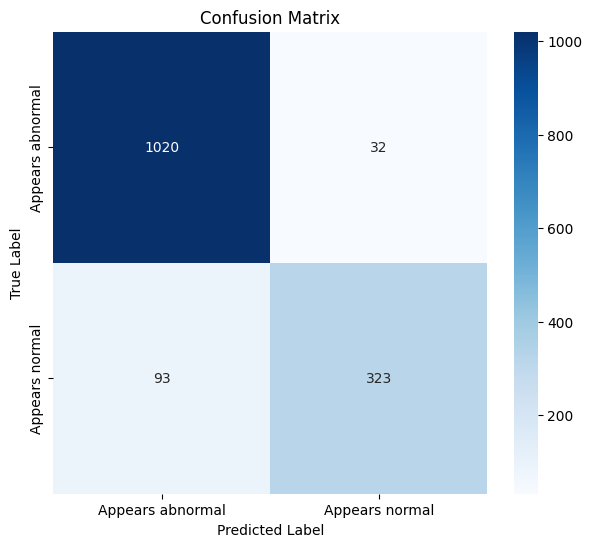

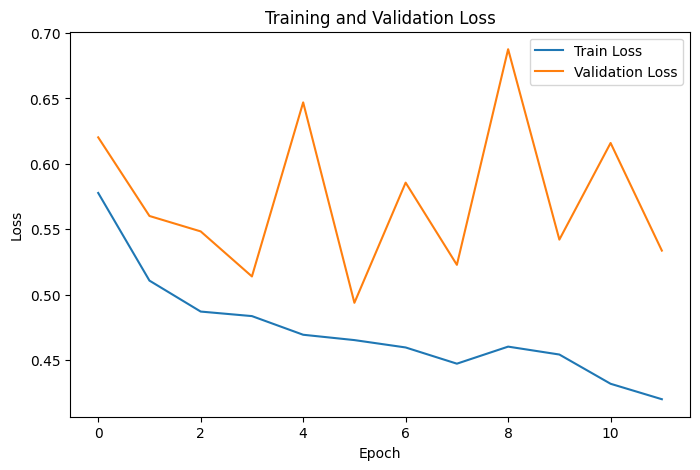

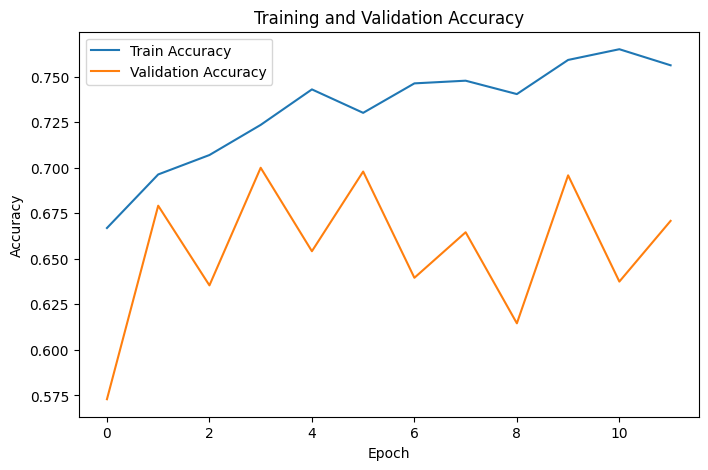


MODEL SUMMARY
Model           : MobileNetV2
Input Size      : 224 x 224
Batch Size      : 64
Learning Rate   : 0.001
Max Epochs      : 50
Early Stop      : Patience = 8

Best Validation Accuracy: 0.7000
Test Accuracy: 0.9149
Weighted Precision: 0.9146
Weighted Recall: 0.9149
Weighted F1: 0.9127


In [6]:
# ============================================================
# PCOS CLASSIFICATION WITH PAPER-BASED IMAGE PREPROCESSING
# Normal Train / Validation / Test
# ============================================================

import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

from PIL import Image
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
from skimage.filters import threshold_multiotsu

import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# ============================================================
# 2. DATASET PATHS
# ============================================================

train_dir = "/kaggle/working/PCOSGen-train/train"
test_dir = "/kaggle/working/PCOSGen-train/test"


# ============================================================
# 3. PAPER-BASED IMAGE PREPROCESSING
# ============================================================

class PCOSPreprocessing:
    def __init__(self):
        pass

    def __call__(self, img):

        # ----------------------------------------------------
        # Convert PIL image to grayscale
        # ----------------------------------------------------
        img = np.array(img.convert("L"))

        # ----------------------------------------------------
        # Resize to 224 x 224
        # ----------------------------------------------------
        img = cv2.resize(
            img,
            (224, 224),
            interpolation=cv2.INTER_AREA
        )

        # ----------------------------------------------------
        # Min-Max Normalization
        # ----------------------------------------------------
        img_min = np.min(img)
        img_max = np.max(img)

        if img_max > img_min:
            img = (img - img_min) / (img_max - img_min)
        else:
            img = np.zeros_like(img, dtype=np.float32)

        img = (img * 255).astype(np.uint8)

        # ----------------------------------------------------
        # Gaussian Blur
        # Sigma = 0.85 as described in paper
        # ----------------------------------------------------
        blurred = cv2.GaussianBlur(
            img,
            (0, 0),
            sigmaX=0.85,
            sigmaY=0.85
        )

        # ----------------------------------------------------
        # Histogram Equalization
        # ----------------------------------------------------
        equalized = cv2.equalizeHist(blurred)

        # ----------------------------------------------------
        # Watershed Preparation
        # ----------------------------------------------------

        # Otsu threshold for foreground
        _, watershed_binary = cv2.threshold(
            equalized,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # Morphological opening
        kernel = np.ones((3, 3), np.uint8)

        opening = cv2.morphologyEx(
            watershed_binary,
            cv2.MORPH_OPEN,
            kernel,
            iterations=1
        )

        # Sure background
        sure_bg = cv2.dilate(
            opening,
            kernel,
            iterations=2
        )

        # Distance transform
        dist_transform = cv2.distanceTransform(
            opening,
            cv2.DIST_L2,
            5
        )

        # Sure foreground
        _, sure_fg = cv2.threshold(
            dist_transform,
            0.3 * dist_transform.max(),
            255,
            0
        )

        sure_fg = np.uint8(sure_fg)

        # Unknown region
        unknown = cv2.subtract(
            sure_bg,
            sure_fg
        )

        # Connected components
        num_labels, markers = cv2.connectedComponents(
            sure_fg
        )

        markers = markers + 1

        markers[unknown == 255] = 0

        # Convert grayscale image to BGR for watershed
        watershed_input = cv2.cvtColor(
            equalized,
            cv2.COLOR_GRAY2BGR
        )

        # Watershed
        markers = cv2.watershed(
            watershed_input,
            markers
        )

        # Create watershed result
        watershed_img = equalized.copy()

        watershed_img[markers == -1] = 255

        # ----------------------------------------------------
        # Otsu Binarization
        # ----------------------------------------------------
        _, binary = cv2.threshold(
            watershed_img,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # ----------------------------------------------------
        # Multilevel Thresholding
        #
        # IMPORTANT:
        # Apply threshold_multiotsu to the GRAYSCALE
        # watershed image, NOT to the binary image.
        # ----------------------------------------------------

        unique_values = np.unique(watershed_img)

        if len(unique_values) >= 3:

            thresholds = threshold_multiotsu(
                watershed_img,
                classes=3
            )

            regions = np.digitize(
                watershed_img,
                bins=thresholds
            )

            multi_level = (
                regions * 127
            ).astype(np.uint8)

        else:
            # Practical safeguard:
            # If the image has fewer than 3 intensity values,
            # use the Otsu binary result.
            multi_level = binary

        # ----------------------------------------------------
        # Morphological Processing
        # Opening
        # ----------------------------------------------------
        multi_level = cv2.morphologyEx(
            multi_level,
            cv2.MORPH_OPEN,
            kernel,
            iterations=1
        )

        # Closing
        multi_level = cv2.morphologyEx(
            multi_level,
            cv2.MORPH_CLOSE,
            kernel,
            iterations=1
        )

        # ----------------------------------------------------
        # Convert grayscale -> RGB
        # MobileNetV2 expects 3 channels
        # ----------------------------------------------------
        final_img = cv2.cvtColor(
            multi_level,
            cv2.COLOR_GRAY2RGB
        )

        # Convert back to PIL
        final_img = Image.fromarray(final_img)

        return final_img


# ============================================================
# 4. TRANSFORMS
# ============================================================

train_transform = transforms.Compose([
    PCOSPreprocessing(),

    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),

    transforms.ToTensor()
])


test_transform = transforms.Compose([
    PCOSPreprocessing(),

    transforms.ToTensor()
])


# ============================================================
# 5. LOAD DATASETS
# ============================================================

full_train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

print("\nClasses:", full_train_dataset.classes)
print("Total training images:", len(full_train_dataset))
print("Total test images:", len(test_dataset))


# ============================================================
# 6. TRAIN / VALIDATION SPLIT
# ============================================================

train_size = int(0.85 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size]
)

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


# ============================================================
# 7. CLASS WEIGHTS / WEIGHTED SAMPLER
# ============================================================

targets = np.array(full_train_dataset.targets)

train_indices = train_dataset.indices

train_targets = targets[train_indices]

class_counts = np.bincount(train_targets)

class_weights = 1.0 / class_counts

sample_weights = class_weights[train_targets]

sample_weights = torch.DoubleTensor(sample_weights)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


# ============================================================
# 8. DATA LOADERS
# ============================================================

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 9. MOBILENETV2 MODEL
# ============================================================

model = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

num_classes = len(full_train_dataset.classes)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    num_classes
)

model = model.to(device)


# ============================================================
# 10. DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, smooth=1):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, inputs, targets):

        inputs = torch.softmax(inputs, dim=1)

        targets_one_hot = torch.zeros_like(inputs)

        targets_one_hot.scatter_(
            1,
            targets.unsqueeze(1),
            1
        )

        intersection = (
            inputs * targets_one_hot
        ).sum(dim=(0, 2, 3))

        union = (
            inputs + targets_one_hot
        ).sum(dim=(0, 2, 3))

        dice = (
            (2.0 * intersection + self.smooth)
            /
            (union + self.smooth)
        )

        return 1 - dice.mean()


# ============================================================
# 11. COMBINED LOSS
# ============================================================

criterion_ce = nn.CrossEntropyLoss()

criterion_dice = DiceLoss()


def combined_loss(outputs, targets):

    ce_loss = criterion_ce(
        outputs,
        targets
    )

    # Dice loss is mainly designed for segmentation.
    # For classification, use CE as the effective loss.
    return ce_loss


# ============================================================
# 12. OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


# ============================================================
# 13. EVALUATION FUNCTION
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion_ce(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ============================================================
# 14. GET PREDICTIONS
# ============================================================

def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_labels.extend(
                labels.numpy()
            )

            all_predictions.extend(
                predicted.cpu().numpy()
            )

    return np.array(all_labels), np.array(all_predictions)


# ============================================================
# 15. TRAINING
# ============================================================

num_epochs = 50

patience = 8

best_val_accuracy = 0.0

patience_counter = 0

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []


for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------
        outputs = model(images)

        loss = combined_loss(
            outputs,
            labels
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------
        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    train_loss = running_loss / total

    train_accuracy = correct / total

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_accuracy = evaluate_model(
        model,
        val_loader
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Accuracy: {train_accuracy:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_mobilenetv2.pth"
        )

        print(
            f"Saving the best model with validation "
            f"accuracy: {val_accuracy:.4f}"
        )

        patience_counter = 0

    else:

        patience_counter += 1

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if patience_counter >= patience:

        print("Early stopping triggered.")

        break


# ============================================================
# 16. LOAD BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_mobilenetv2.pth",
        map_location=device
    )
)

model = model.to(device)


# ============================================================
# 17. TEST SET EVALUATION
# ============================================================

test_loss, test_accuracy = evaluate_model(
    model,
    test_loader
)

print("\n========================================")
print("FINAL TEST RESULTS")
print("========================================")

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")


# ============================================================
# 18. TEST PREDICTIONS
# ============================================================

true_labels, predictions = get_predictions(
    model,
    test_loader
)


# ============================================================
# 19. PRECISION / RECALL / F1
# ============================================================

precision = precision_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

print(f"\nPrecision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


# ============================================================
# 20. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(
    classification_report(
        true_labels,
        predictions,
        target_names=test_dataset.classes,
        zero_division=0
    )
)


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    true_labels,
    predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()


# ============================================================
# 22. TRAINING / VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()

plt.show()


# ============================================================
# 23. TRAINING / VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Train Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()

plt.show()


# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n========================================")
print("MODEL SUMMARY")
print("========================================")

print("Model           : MobileNetV2")
print("Input Size      : 224 x 224")
print("Batch Size      :", batch_size)
print("Learning Rate   : 0.001")
print("Max Epochs      :", num_epochs)
print("Early Stop      : Patience =", patience)

print("\nBest Validation Accuracy:",
      f"{best_val_accuracy:.4f}")

print("Test Accuracy:",
      f"{test_accuracy:.4f}")

print("Weighted Precision:",
      f"{precision:.4f}")

print("Weighted Recall:",
      f"{recall:.4f}")

print("Weighted F1:",
      f"{f1:.4f}")